# 1. What a recording is, for a computer

This series explains, step by step, how **SongPolish** improves a voice + guitar recording.
It assumes you know programming, basic data science (arrays, plots, statistics) and the
basic ideas of machine learning, but **nothing about sound or music**.

| Notebook | Topic |
|---|---|
| **1 (this one)** | What digital sound is: samples, frequency, pitch, harmonics, spectra, loudness |
| 2 | Music theory for machines: notes, scales, keys, chords, and how the app reads them from the guitar |
| 3 | Finding the sung notes: pitch tracking and note segmentation |
| 4 | Choosing the right note: out-of-tune vs wrong notes, and the strategies that decide |
| 5 | Moving notes without artefacts: pitch shifting, and the bugs we had to fix |
| 6 | Separating voice and guitar with a neural network, and why the final song does not depend on it |
| 7 | Cleaning and mastering: noise, EQ, compression, reverb, loudness |
| 8 | The whole pipeline on a real song |

Every example runs the project's own code (`src/songpolish`). Most use **synthetic sounds**, because then we
know the exact truth (for example "this note is 30 cents sharp") and can check every measurement.

Press the ▶ buttons to listen. Headphones help.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")  # hide library chatter (progress bars etc.)
import numpy as np
import matplotlib.pyplot as plt
import librosa
from nbtools import *   # synthetic sounds, play(), plots (see nbtools.py)
plt.rcParams["figure.dpi"] = 90

## 1.1 Sound is a list of numbers

Sound is air pressure going up and down very fast. A microphone turns that pressure into a voltage,
and the computer measures the voltage many times per second. Each measurement is a **sample**.

* The **sample rate** is how many samples per second. The app works at **44,100 samples/s** (CD quality).
* A sample is a number, here a `float32` between −1 and +1 (0 = silence, ±1 = the loudest possible).
* A stereo recording has two lists (left, right). In the code, audio is always an array of shape
  **`(channels, samples)`**: a 4-minute mono song is `(1, 10_584_000)`.

Why 44,100? Human hearing goes up to about 20,000 vibrations per second. To capture a vibration you need
at least two samples per cycle (one up, one down). That is the **Nyquist** rule: the sample rate must be
more than twice the highest frequency, so 44,100 covers up to 22,050.

Let's make the simplest sound: a **sine wave** that repeats 440 times per second.

shape: (88200,)  dtype: float32  first samples: [0.    0.019 0.038 0.056 0.074]


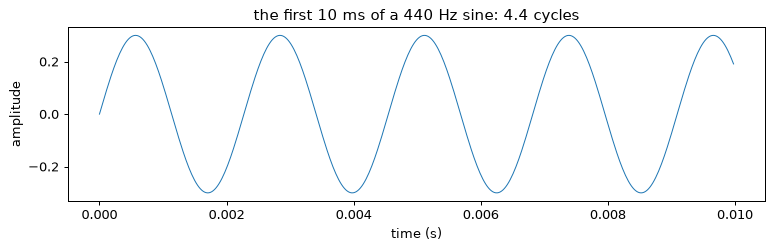

In [2]:
tone = sine(440, seconds=2.0)
print("shape:", tone.shape, " dtype:", tone.dtype, " first samples:", np.round(tone[:5], 3))
plot_wave(tone, seconds=0.01, title="the first 10 ms of a 440 Hz sine: 4.4 cycles")
plt.show()
play(tone)

## 1.2 Frequency is pitch

How many times per second the wave repeats is its **frequency**, measured in **Hertz (Hz)**.
We hear frequency as **pitch**: more Hz = higher note.

Pitch perception is **logarithmic**: what sounds like "the same step up" is a *multiplication* of frequency,
not an addition.

* Doubling the frequency is an **octave** (220 → 440 → 880 Hz all sound like "the same note", higher and higher).
* Western music divides the octave into **12 equal steps** called **semitones**. One semitone is a factor of
  $2^{1/12} \approx 1.0595$.
* One semitone is divided into **100 cents**. "The voice is 20 cents sharp" means a fifth of a semitone too high.
  Most listeners notice about 10–25 cents, depending on the context.

To compute with pitch, the app uses **MIDI note numbers**: one number per semitone, with 69 = 440 Hz.

$$f = 440 \cdot 2^{(m - 69)/12} \qquad\Longleftrightarrow\qquad m = 69 + 12 \log_2(f / 440)$$

On this scale, pitch arithmetic becomes ordinary subtraction: a note at $m = 60.3$ is a C (60) that is
30 cents sharp. Fractional MIDI numbers are how the app stores sung pitch.

In [3]:
for m in [57, 60, 60.3, 69, 81]:
    print(f"MIDI {m:5}: {midi_to_hz(m):7.1f} Hz  ({note_name(m)}{'' if m == int(m) else f', {100*(m-round(m)):+.0f} cents'})")

MIDI    57:   220.0 Hz  (A3)
MIDI    60:   261.6 Hz  (C4)
MIDI  60.3:   266.2 Hz  (C4, +30 cents)
MIDI    69:   440.0 Hz  (A4)
MIDI    81:   880.0 Hz  (A5)


Listen to what "out of tune" means. First a 440 Hz tone together with a correct one, then with one that is
**25 cents** sharp. When two close frequencies play together they **beat**: the loudness wobbles at the
difference frequency (here about 6 times per second). Musicians hear that wobble as "out of tune".

440 Hz + 440 Hz (in tune)


440 Hz + 446.4 Hz (25 cents apart: you hear a slow wobble)


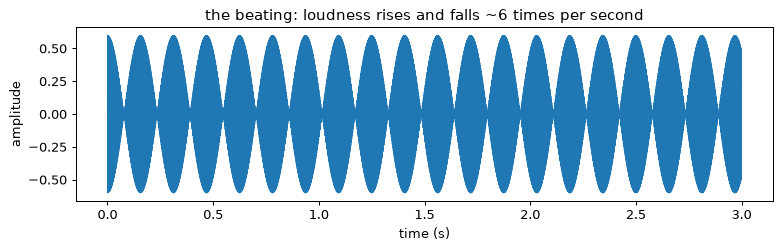

In [4]:
in_tune = sine(440, 3) + sine(440, 3)
sharp = sine(440, 3) + sine(midi_to_hz(69.25), 3)
play(in_tune, label="440 Hz + 440 Hz (in tune)")
play(sharp, label="440 Hz + 446.4 Hz (25 cents apart: you hear a slow wobble)")
plot_wave(sharp, title="the beating: loudness rises and falls ~6 times per second")
plt.show()

## 1.3 Harmonics: why a voice is not a sine

A real instrument vibrating at 220 Hz also vibrates at 440, 660, 880 Hz… (integer multiples). These are
**harmonics** (or overtones). The lowest one, the **fundamental** ($f_0$), sets the pitch we hear. How strong
each harmonic is gives the **timbre**, which is why a voice and a guitar playing the same note sound different.

`voice_like` (in `nbtools.py`) builds a crude "voice": 11 harmonics that get weaker as they go up, plus
**vibrato** (the pitch wobbling ±25 cents about 5.5 times per second, as singers do) and a little breath noise.

sine at 220 Hz


'voice' at 220 Hz: same pitch, different timbre


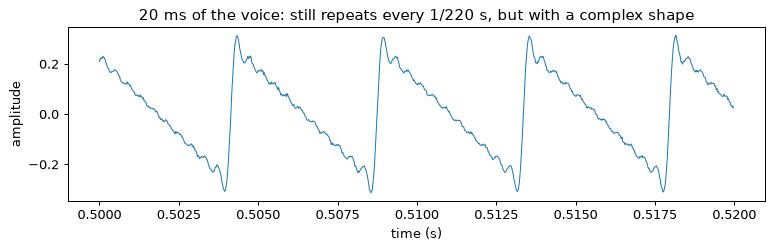

In [5]:
pure = sine(220, 1.5)
voice = voice_like([57], note_s=1.5)   # MIDI 57 = A3 = 220 Hz
play(pure, label="sine at 220 Hz")
play(voice, label="'voice' at 220 Hz: same pitch, different timbre")
plot_wave(voice, start_s=0.5, seconds=0.02, title="20 ms of the voice: still repeats every 1/220 s, but with a complex shape")
plt.show()

## 1.4 The spectrum: which frequencies are inside a sound

The waveform is hard to read. The **Fourier transform** rewrites a signal as a sum of sines and tells you
how strong each frequency is. If you think in linear algebra, it is a **change of basis**: from "value at each
time" to "amount of each frequency". The fast algorithm is the **FFT**.

The spectrum of our voice shows peaks at 220, 440, 660 Hz…, i.e. its harmonics. The vertical axis is in
**decibels**, explained next.

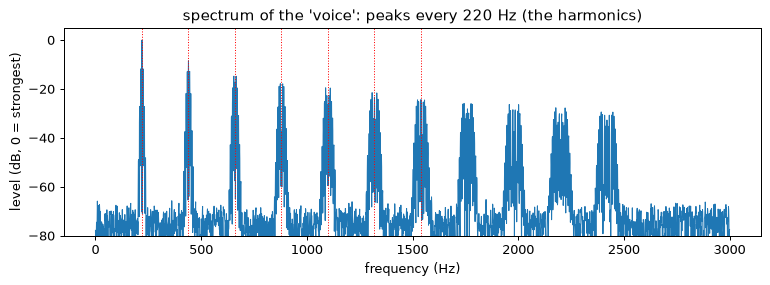

In [6]:
ax = plot_spectrum(voice[0, :44100], fmax=3000, title="spectrum of the 'voice': peaks every 220 Hz (the harmonics)")
for k in range(1, 8):
    ax.axvline(220 * k, color="r", ls=":", lw=0.8)
plt.show()

## 1.5 Decibels

Loudness also feels logarithmic, so levels are measured in **decibels (dB)**, a log scale of a ratio:

$$\text{dB} = 20 \log_{10}\!\left(\frac{\text{amplitude}}{\text{reference amplitude}}\right)$$

| change | in amplitude |
|---|---|
| +6 dB | ×2 |
| −6 dB | ×0.5 |
| −20 dB | ×0.1 |
| −60 dB | ×0.001 (barely audible next to the original) |

"dBFS" means relative to the loudest possible sample (FS = full scale), so 0 dBFS is the maximum and
everything real is negative. When this series says "the leftover voice is at −12 dB", it means
4× weaker in amplitude than the voice.

In [7]:
for db in [6, -6, -12, -20, -40, -60]:
    print(f"{db:+4d} dB = amplitude x {10 ** (db / 20):.4f}")

  +6 dB = amplitude x 1.9953
  -6 dB = amplitude x 0.5012
 -12 dB = amplitude x 0.2512
 -20 dB = amplitude x 0.1000
 -40 dB = amplitude x 0.0100
 -60 dB = amplitude x 0.0010


## 1.6 Spectrograms: the spectrum over time

Music changes over time, so one spectrum for the whole song is not enough. The **short-time Fourier
transform (STFT)** cuts the signal into short overlapping **frames** (e.g. 2048 samples ≈ 46 ms, moved forward
by a **hop** of 256 samples) and takes the spectrum of each frame. The result is a 2-D array,
**frequency × time**, which you can treat like an image or a feature matrix. Most of the app's analysis
works on such matrices.

There is a trade-off, like an uncertainty principle: long frames give sharp frequencies but blurry timing,
short frames the opposite.

Below: a melody of four notes, one of them a semitone off.

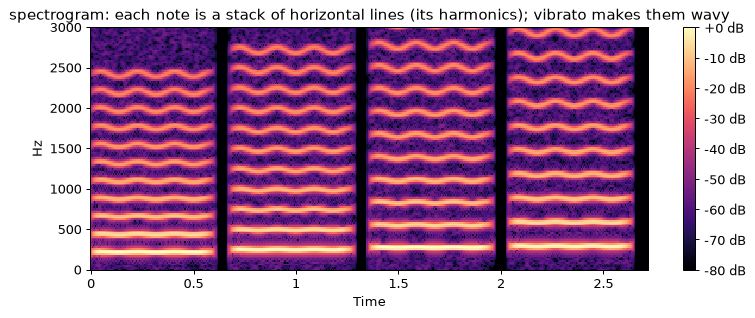

In [8]:
melody = voice_like([57, 59, 61, 62], note_s=0.6)
play(melody)
plot_spectrogram(melody, fmax=3000, title="spectrogram: each note is a stack of horizontal lines (its harmonics); vibrato makes them wavy")
plt.show()

## 1.7 Loudness the way people hear it: LUFS

Two recordings with the same peak level can sound very different in loudness. The broadcast standard
**LUFS** (Loudness Units relative to Full Scale, ITU-R BS.1770) measures loudness as people hear it:

1. Weight the frequencies the way the ear does ("K-weighting": less bass, a bit more presence).
2. Measure the energy in 400 ms blocks.
3. Ignore silent blocks (gating) and average the rest.

Streaming services play songs at about **−14 LUFS**, so the app masters to that. A phone take is
often around −21 LUFS. "1 LU" is the same step size as 1 dB.

One important consequence, used later: **louder always sounds better** to our ears. So when the app
gives you the original for comparison, it gives it at exactly the same loudness ("honest A/B").

In [9]:
from songpolish.analysis import loudness_lufs
quiet = 0.1 * melody
print(f"melody:            {loudness_lufs(melody):6.1f} LUFS")
print(f"melody x 0.1:      {loudness_lufs(quiet):6.1f} LUFS  (x0.1 = -20 dB, so 20 LU quieter)")
low = voice_like([33], note_s=2.0)    # the same 'voice' 2 octaves lower, same amplitude
high = voice_like([81], note_s=2.0)   # and 2 octaves higher
print(f"low voice:         {loudness_lufs(low):6.1f} LUFS")
print(f"high voice:        {loudness_lufs(high):6.1f} LUFS  (same amplitude, but the ear finds it louder)")

melody:             -17.4 LUFS
melody x 0.1:       -37.4 LUFS  (x0.1 = -20 dB, so 20 LU quieter)
low voice:          -18.9 LUFS
high voice:         -15.1 LUFS  (same amplitude, but the ear finds it louder)


## Summary

* A recording is an array `(channels, samples)` of floats in [−1, 1], 44,100 samples per second.
* **Frequency** (Hz) is heard as **pitch**, on a log scale: octave = ×2, semitone = ×2^(1/12), 100 cents per semitone.
  The app stores pitch as fractional **MIDI numbers**, so "how far off" is a subtraction.
* Real sounds are a fundamental plus **harmonics**; the harmonic mix is the **timbre**.
* The **spectrum** (FFT) shows which frequencies are present; the **spectrogram** (STFT) shows it over time.
* Levels are in **dB**; perceived loudness in **LUFS**.

Next: **notebook 2**, music theory for machines.